<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/05_cnn_baseline_MFM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

tf.keras.utils.set_random_seed(42)

DATASET_DIR = "/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/DATA MENTAH"

OUTPUT_DIR = os.path.dirname(DATASET_DIR)

data = np.load(os.path.join(OUTPUT_DIR, "dataset_split.npz"))

X_train = data["X_train"]
X_val = data["X_val"]
X_test = data["X_test"]

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

k_test = data["k_test"]

nama_kelas = ["TAS", "BUKU GAMBAR", "LAPTOP"]

print("DATA CNN BASELINE BERHASIL DIBACA")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)


DATA CNN BASELINE BERHASIL DIBACA
Training: (84, 128, 128, 3)
Validation: (18, 128, 128, 3)
Testing: (18, 128, 128, 3)


In [15]:

model_cnn = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation="relu"),

    tf.keras.layers.Dense(3, activation="softmax")
])

model_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_cnn.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     3,686,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,706,051 (14.14 MB)

 Trainable params: 3,706,051 (14.14 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model_cnn.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=8,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    verbose=1
)

print("TRAINING CNN BASELINE SELESAI!")


Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 224ms/step - accuracy: 0.3810 - loss: 1.3398 - val_accuracy: 0.6111 - val_loss: 0.9925
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 190ms/step - accuracy: 0.7381 - loss: 0.8129 - val_accuracy: 0.7222 - val_loss: 0.7350
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 193ms/step - accuracy: 0.9405 - loss: 0.3817 - val_accuracy: 0.7222 - val_loss: 0.5343
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 187ms/step - accuracy: 0.9048 - loss: 0.2121 - val_accuracy: 0.5556 - val_loss: 0.6051
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 320ms/step - accuracy: 0.9524 - loss: 0.1592 - val_accuracy: 0.4444 - val_loss: 1.8464
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 190ms/step - accuracy: 0.9167 - loss: 0.2830 - val_accuracy: 0.7222 - val_loss: 0.5768
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 187ms/step - accuracy: 1.0000 - loss: 0.0382 - val_accuracy: 0.7222 - val_loss: 0.4282
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 189ms/step - accuracy: 1.0000 - loss: 0.0171 - val_accuracy: 0.

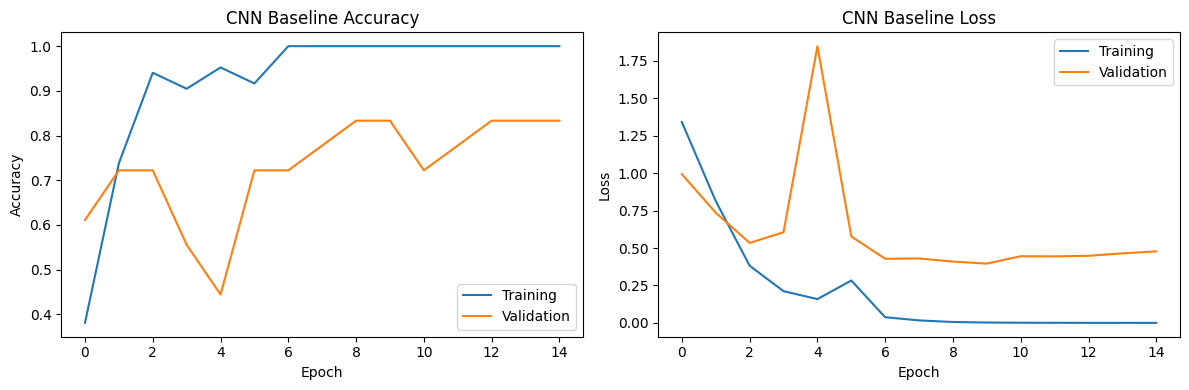

In [17]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Baseline Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Baseline Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [18]:

hasil_test = model_cnn.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("HASIL TESTING CNN BASELINE")
print("Test Loss:", round(hasil_test[0], 4))
print("Test Accuracy:", round(hasil_test[1] * 100, 2), "%")

prediksi_prob = model_cnn.predict(X_test)

pred_cnn = np.argmax(prediksi_prob, axis=1)

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    pred_cnn,
    labels=[0, 1, 2],
    target_names=nama_kelas,
    zero_division=0
))


HASIL TESTING CNN BASELINE
Test Loss: 0.8773
Test Accuracy: 72.22 %
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step

CLASSIFICATION REPORT
              precision    recall  f1-score   support

         TAS       0.62      0.83      0.71         6
 BUKU GAMBAR       0.75      1.00      0.86         6
      LAPTOP       1.00      0.33      0.50         6

    accuracy                           0.72        18
   macro avg       0.79      0.72      0.69        18
weighted avg       0.79      0.72      0.69        18



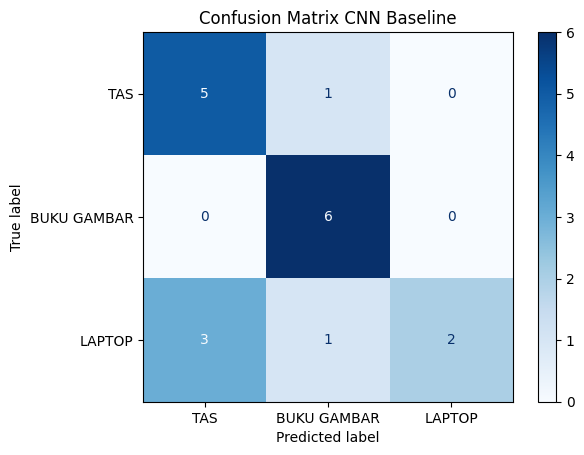

In [19]:

cm = confusion_matrix(
    y_test,
    pred_cnn,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=nama_kelas
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix CNN Baseline")
plt.show()


In [20]:

print("EVALUASI CNN BERDASARKAN KONDISI")
print("=" * 40)

for kondisi in ["KONDISI IDEAL", "KONDISI SULIT"]:

    indeks = np.where(k_test == kondisi)[0]

    akurasi = accuracy_score(
        y_test[indeks],
        pred_cnn[indeks]
    )

    print(kondisi)
    print("Jumlah gambar:", len(indeks))
    print("Akurasi:", round(akurasi * 100, 2), "%")
    print("-" * 40)


EVALUASI CNN BERDASARKAN KONDISI
KONDISI IDEAL
Jumlah gambar: 9
Akurasi: 66.67 %
----------------------------------------
KONDISI SULIT
Jumlah gambar: 9
Akurasi: 77.78 %
----------------------------------------


In [21]:

MODEL_FILE = os.path.join(
    OUTPUT_DIR,
    "model_cnn_baseline.keras"
)

model_cnn.save(MODEL_FILE)

print("MODEL CNN BASELINE BERHASIL DISIMPAN!")
print(MODEL_FILE)


MODEL CNN BASELINE BERHASIL DISIMPAN!
/content/drive/.shortcut-targets-by-id/1LoCHPgLL2xzbYllXiCpFE89B8TmW7Efs/COMPUTER VISION_TI 2026/kelompok 3/KLASIFIKASI CITRA DENGAN CNN/model_cnn_baseline.keras
